# Activité Pratique N°5 — Partie D : Synthèse

## Système multi-agents de SAV d'un distributeur d'électronique



LLM local : **qwen3-vl:2b-instruct** (Ollama) · Embeddings : **nomic-embed-text**

| Fichier | Rôle |
|---|---|
| `data/manuels/manuel_PX-200.pdf` | Manuel technique (texte + pictogrammes) |
| `data/images/img_px200_01.png` | Photo jointe par le client |
| `data/registre_garanties.json` | Registre des garanties |
| `mcp_server.py` | Serveur MCP + agent RAG multimodal |
| `sav_graph.py` | Orchestrateur et agents spécialisés |

## 1. Données du SAV

In [1]:
import json
from pathlib import Path
import pymupdf
from IPython.display import Image, Markdown, display

DATA = Path("data")
manuel = pymupdf.open(DATA / "manuels" / "manuel_PX-200.pdf")
print("Manuel :", manuel.page_count, "pages")
for numero, page in enumerate(manuel, start=1):
    print(f"  page {numero} : {len(page.get_images())} figure(s) — {page.get_text().splitlines()[0]}")

print("\nRegistre des garanties :")
print(json.dumps(json.loads((DATA / "registre_garanties.json").read_text(encoding="utf-8")), indent=2, ensure_ascii=False))

Manuel : 4 pages
  page 1 : 0 figure(s) — Imprimante PX-200
  page 2 : 2 figure(s) — 3. Voyants et pictogrammes du panneau
  page 3 : 2 figure(s) — 3. Voyants et pictogrammes du panneau (suite)
  page 4 : 0 figure(s) — 4. Remplacement des cartouches

Registre des garanties :
{
  "PX200-0042": {
    "modele": "PX-200",
    "client": "Client A",
    "date_achat": "2025-03-14",
    "duree_mois": 24
  },
  "PX200-0007": {
    "modele": "PX-200",
    "client": "Client B",
    "date_achat": "2023-06-02",
    "duree_mois": 24
  },
  "PX200-0315": {
    "modele": "PX-200",
    "client": "Client C",
    "date_achat": "2026-09-30",
    "duree_mois": 24
  }
}


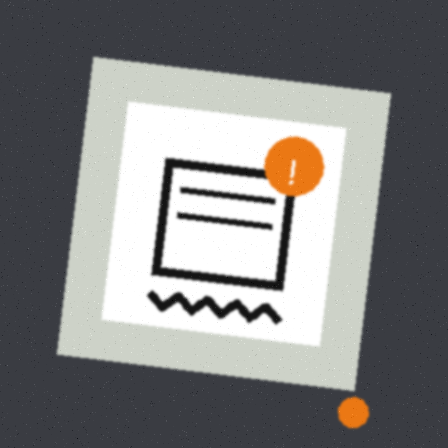

In [2]:
# Photo jointe par le client (référence img_px200_01)
display(Image(filename=DATA / "images" / "img_px200_01.png", width=260))

## 2. Serveur MCP

Dans un **terminal séparé** (laisser tourner) :

```
uv run mcp_server.py
```

Le serveur indexe le manuel (passages + figures) puis écoute sur `http://localhost:24000/mcp`.

**Test avec MCP Inspector** :

```
npx @modelcontextprotocol/inspector
```

Transport **Streamable HTTP**, URL `http://localhost:24000/mcp` → *Connect* → *Tools* → `rag_multimodal`.

manuel_PX-200_p2_fig1.png


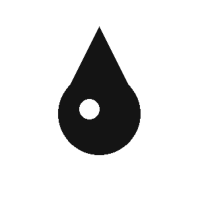

manuel_PX-200_p2_fig2.png


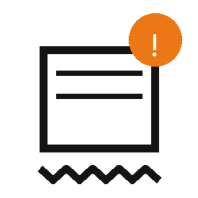

manuel_PX-200_p3_fig1.png


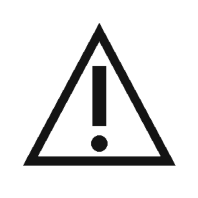

manuel_PX-200_p3_fig2.png


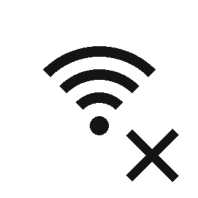

In [3]:
# Figures extraites du manuel par le serveur au moment de l'indexation
for figure in sorted((DATA / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=figure, width=110))

## 3. Client MCP : découverte et appel du tool distant

In [4]:
from langchain_mcp_adapters.client import MultiServerMCPClient

client = MultiServerMCPClient({"sav": {"transport": "streamable_http", "url": "http://localhost:24000/mcp",
                                       "timeout": 60, "sse_read_timeout": 1200}})
outils = await client.get_tools()
for outil in outils:
    print(outil.name, "→", outil.description[:120], "...")
    print("   paramètres :", list(outil.args_schema["properties"]))

rag_multimodal → Rechercher dans les manuels techniques des imprimantes (passages de texte et figures/pictogrammes)
    et retourner une  ...
   paramètres : ['question', 'image_ref']


In [5]:
from sav_graph import texte

rag_multimodal = outils[0]
resultat = await rag_multimodal.ainvoke({"question": "Que signifie le pictogramme de la photo ?", "image_ref": "img_px200_01"})
display(Markdown(texte(resultat)))

Le pictogramme décrit dans votre description correspond à l'erreur de la tête d'impression. Il s'agit du **pictogramme de l'erreur de la tête d'impression** (Figure 4) du manuel **PX-200.pdf**, page 3.

Le pictogramme indique un problème technique avec la tête d'impression de l'imprimante. Si l'erreur persiste après deux nettoyages, il est recommandé de contacter le service après-vente (SAV).

Sources :
- manuel_PX-200.pdf, page 3 — Figure 4 – Pictogramme « triangle d'avertissement » : erreur tête d'impression. (data\figures\manuel_PX-200_p3_fig1.png)
- manuel_PX-200.pdf, page 2 — Figure 2 – Pictogramme « feuille et vague » : bourrage papier. (data\figures\manuel_PX-200_p2_fig2.png)

## 4. Tool local : `consulter_garantie`

In [6]:
from sav_graph import consulter_garantie

for numero in ("PX200-0042", "PX200-0007", "PX200-9999"):
    print(consulter_garantie.invoke({"numero_serie": numero}))

{'numero_serie': 'PX200-0042', 'trouve': True, 'modele': 'PX-200', 'date_achat': '2025-03-14', 'fin_garantie': '2027-03-14', 'sous_garantie': True, 'jours_restants': 109}
{'numero_serie': 'PX200-0007', 'trouve': True, 'modele': 'PX-200', 'date_achat': '2023-06-02', 'fin_garantie': '2025-06-02', 'sous_garantie': False, 'jours_restants': 0}
{'numero_serie': 'PX200-9999', 'trouve': False}


## 5. Orchestrateur LangGraph

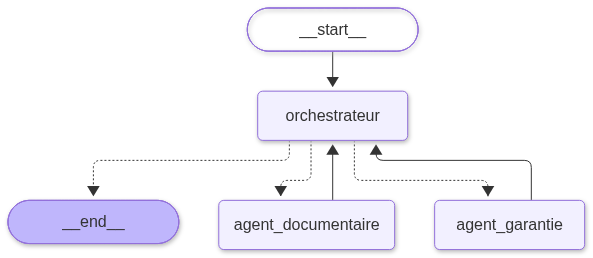

In [7]:
from sav_graph import construire_systeme, traiter_demande
from langgraph.checkpoint.memory import InMemorySaver

systeme = await construire_systeme(checkpointer=InMemorySaver())

try:
    display(Image(systeme.get_graph().draw_mermaid_png()))
except Exception:
    print(systeme.get_graph().draw_mermaid())

In [8]:
import time
from langchain.messages import AIMessage, ToolMessage
compteur = 0


async def sav(question, image_ref=None):
    global compteur
    compteur += 1
    debut = time.time()
    config = {"configurable": {"thread_id": f"client-{compteur}"}}
    etat = {"messages": [{"role": "user", "content": question}], "question": question, "image_ref": image_ref,
            "categorie": None, "agent": None, "reponse_finale": None}
    noeuds = []
    async for etape in systeme.astream(etat, config=config, stream_mode="updates"):
        noeuds.extend(etape)
    final = systeme.get_state(config).values
    appels = [f"{a['name']}({a['args']})" for m in final["messages"] if isinstance(m, AIMessage) for a in m.tool_calls]
    print("Parcours :", " → ".join(noeuds))
    print("Catégorie :", final["categorie"], "| Agent :", final["agent"], f"| {time.time() - debut:.0f} s")
    print("Appels de tools :", appels or "appel direct (repli)")
    display(Markdown(f"**Client :** {question}" + (f" *(photo : {image_ref})*" if image_ref else "")
                     + f"\n\n**Réponse :**\n\n{final['reponse_finale']}"))

## 6. Exemples de la consigne

In [9]:
await sav("Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?",
          image_ref="img_px200_01")

[orchestrateur] catégorie = documentation
[orchestrateur] réponse reçue de agent_documentaire → fin
Parcours : orchestrateur → agent_documentaire → orchestrateur
Catégorie : documentation | Agent : agent_documentaire | 93 s
Appels de tools : ["rag_multimodal({'question': 'Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?', 'image_ref': 'img_px200_01'})"]


**Client :** Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ? *(photo : img_px200_01)*

**Réponse :**

Le pictogramme affiché sur l'écran de l'imprimante PX-200 correspond à un **erreur de la tête d'impression**. Il s'agit du **pictogramme de type « triangle d'avertissement »** illustré dans la figure 4 du manuel **manuel_PX-200.pdf** (page 3).

**Signification du pictogramme :**  
L'erreur de la tête d'impression indique que la tête d'impression de l'imprimante est bloquée ou mal positionnée. Pour résoudre ce problème, il faut suivre les instructions suivantes :

1. Lancer un nettoyage de la tête depuis le menu **Maintenance**.
2. Si l'erreur persiste après deux nettoyages, contacter le service après-vente (SAV).

Sources :
- manuel_PX-200.pdf, page 3 — Figure 4 – Pictogramme « triangle d'avertissement » : erreur tête d'impression. (data\figures\manuel_PX-200_p3_fig1.png)
- manuel_PX-200.pdf, page 2 — Figure 2 – Pictogramme « feuille et vague » : bourrage papier. (data\figures\manuel_PX-200_p2_fig2.png)

In [10]:
await sav("Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.")

[orchestrateur] catégorie = garantie
[orchestrateur] réponse reçue de agent_garantie → fin
Parcours : orchestrateur → agent_garantie → orchestrateur
Catégorie : garantie | Agent : agent_garantie | 16 s
Appels de tools : ["consulter_garantie({'numero_serie': 'PX200-0042'})"]


**Client :** Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042.

**Réponse :**

Votre imprimante PX-200, numéro de série PX200-0042, est encore sous garantie.

La garantie est valable jusqu'au **14 mars 2027**, et il reste **109 jours** à ce jour.

## 7. Autres cas

In [11]:
# Garantie expirée
await sav("Ma PX-200 numéro PX200-0007 est-elle encore couverte par la garantie ?")

[orchestrateur] catégorie = garantie
[orchestrateur] réponse reçue de agent_garantie → fin
Parcours : orchestrateur → agent_garantie → orchestrateur
Catégorie : garantie | Agent : agent_garantie | 15 s
Appels de tools : ["consulter_garantie({'numero_serie': 'PX200-0007'})"]


**Client :** Ma PX-200 numéro PX200-0007 est-elle encore couverte par la garantie ?

**Réponse :**

Votre appareil PX-200 (numéro PX200-0007) est encore couvert par la garantie. Il est en période de garantie, avec une date de fin de garantie de **2025-06-02**. Il n'y a pas de jours restants, donc l'appareil est toujours sous garantie.

In [12]:
# Documentation sans photo
await sav("Comment remplacer la cartouche de ma PX-200 ?")

[orchestrateur] catégorie = documentation
[agent_documentaire] appel direct de rag_multimodal
[orchestrateur] réponse reçue de agent_documentaire → fin
Parcours : orchestrateur → agent_documentaire → orchestrateur
Catégorie : documentation | Agent : agent_documentaire | 88 s
Appels de tools : appel direct (repli)


**Client :** Comment remplacer la cartouche de ma PX-200 ?

**Réponse :**

Pour remplacer la cartouche de votre PX-200, suivez ces étapes :

1. **Vérifiez l'état de la cartouche** :  
   - Si le voyant orange fixe avec la goutte indique que la cartouche est presque vide, ou si le voyant orange clignotant avec la goutte signale un cartouche vide ou non reconnu, il est temps de remplacer la cartouche.  
   (Ces indications sont décrites sur les pages 2 et 4 du manuel.)

2. **Ouvrez le capot avant** :  
   - Ouvrez le capot avant de la PX-200.  
   - Attendez que le chariot s'arrête au centre.  
   (Cela est mentionné sur la page 4.)

3. **Insérez la nouvelle cartouche** :  
   - Appuyez sur la cartouche pour la libérer.  
   - Insérez la nouvelle cartouche jusqu'au déclic.  
   (Cela est expliqué sur la page 4.)

4. **Utilisation des cartouches autorisées** :  
   - Utilisez uniquement les cartouches PX-C20 (noir) et PX-C21 (couleur).  
   (Cela est indiqué sur la page 4.)

5. **Contactez le service après-vente** :  
   - Si vous avez des questions ou si vous rencontrez un problème, contactez le service après-vente.  
   (Cela est mentionné sur la page 5.)

> **Note** : La garantie de la PX-200 couvre les pannes matérielles mais pas les cartouches ni les dommages causés par une chute ou un liquide. Le numéro de série est situé sous le capot arrière (page 1).

Sources :
- manuel_PX-200.pdf, page 2 — Figure 1 – Pictogramme « goutte d'encre » : niveau d'encre bas. (data\figures\manuel_PX-200_p2_fig1.png)
- manuel_PX-200.pdf, page 1
- manuel_PX-200.pdf, page 4
- manuel_PX-200.pdf, page 2

In [13]:
# Numéro de série inconnu
await sav("Vérifiez la garantie de l'appareil PX200-9999 s'il vous plaît.")

[orchestrateur] catégorie = garantie
[orchestrateur] réponse reçue de agent_garantie → fin
Parcours : orchestrateur → agent_garantie → orchestrateur
Catégorie : garantie | Agent : agent_garantie | 12 s
Appels de tools : ["consulter_garantie({'numero_serie': 'PX200-9999'})"]


**Client :** Vérifiez la garantie de l'appareil PX200-9999 s'il vous plaît.

**Réponse :**

L'appareil PX200-9999 n'est pas trouvé dans le registre des garanties. Veuillez vérifier le numéro de série avec soin et réessayez. Si vous avez besoin d'aide supplémentaire, n'hésitez pas à me le dire.